数据集大小: (569, 30), 原始特征数: 30
✅ 互信息选出的 Top 10 特征:
['worst perimeter', 'worst area', 'mean concave points', 'worst concave points', 'worst radius', 'mean perimeter', 'mean concavity', 'mean area', 'mean radius', 'area error']


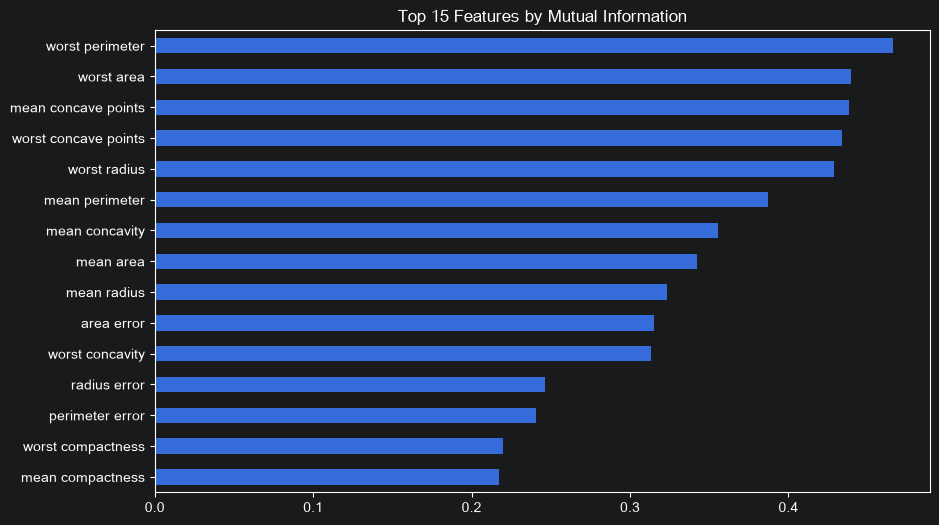

In [10]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 设置中文字体（Mac 用户用这个，Windows 可改回 SimHei）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

# 1. 加载乳腺癌数据集
data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
y = data.target

# 2. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"数据集大小: {X.shape}, 原始特征数: {X.shape[1]}")

from sklearn.feature_selection import mutual_info_classif

# 计算互信息
mi_scores = mutual_info_classif(X_train, y_train)
mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=False)

# 选出 Top 10
TOP_K = 10
mi_features = mi_series.head(TOP_K).index.tolist()
print(f"✅ 互信息选出的 Top {TOP_K} 特征:\n{mi_features}")

# 可视化
plt.figure(figsize=(10, 6))
mi_series.head(15).plot(kind='barh')
plt.title('Top 15 Features by Mutual Information')
plt.gca().invert_yaxis()
plt.show()